# 21 - Stack estático e grelha comum

| | |
|---|---|
| **Tarefa do plano** | S2-04 - reprojeção e reamostragem de todas as camadas para a grelha comum |
| **O que faz** | Junta todas as camadas fixas num só ficheiro alinhado e confirma que tudo está na mesma grelha |
| **Usa** | Camadas estáticas (notebook 02) e todos os rasters mensais |
| **Produz** | `data/interim/features/static_stack_marracuene_30m.tif` |

**Ideia simples.** Para um modelo aprender, o píxel da linha 100, coluna 200 tem de
ser o mesmo pedaço de terreno em todas as camadas. Na Semana 1 todos os rasters
já foram descarregados diretamente na grelha do projeto (EPSG:32736), por isso
aqui não é preciso reprojetar: basta **confirmar** o alinhamento e juntar as
camadas fixas.

A grelha de 10 m encaixa na de 30 m: cada píxel de 30 m contém exatamente 3 × 3
píxeis de 10 m.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Construir o stack estático (30 m)

In [2]:
stack_file = rasters.build_static_stack(cfg)
stack = rasters.read_bands(stack_file)
masks = rasters.study_masks(cfg)
print(stack_file.relative_to(ROOT), f"({stack_file.stat().st_size / 1e6:.0f} MB)")

inside = masks["study"]
resumo = pd.DataFrame({name: {"minimo": np.nanmin(v[inside]), "mediana": np.nanmedian(v[inside]), "maximo": np.nanmax(v[inside]),
                              "sem_dados_pct": 100 * np.isnan(v[inside]).mean()} for name, v in stack.items()}).T
resumo

data/interim/features/static_stack_marracuene_30m.tif (62 MB)


,minimo,mediana,maximo,sem_dados_pct
elevation,-2.443,7.057,90.850,0.000
slope,0.000,0.608,35.693,0.000
aspect,-0.000,115.924,360.000,0.000
hand,0.000,2.300,83.700,20.903
upstream_area_km2,0.008,0.008,"44,910.043",20.903
distance_to_river_m,0.000,"1,831.720","12,294.475",0.000
log_upstream_area,-2.113,-2.112,4.652,20.903
twi,5.882,10.412,27.478,20.903
land_cover,10.000,40.000,95.000,0.000
jrc_occurrence,0.000,0.000,100.000,0.000


**Notas sobre as camadas**

- `hand`, `upstream_area_km2`, `twi`: vêm do MERIT Hydro, que não tem valores sobre
  o mar. Esses cerca de 21 % sem dados são mar aberto e ficam fora do **domínio de
  modelação** (zona de estudo com dados de terreno).
- `distance_to_river_m`: distância ao **canal real do Incomáti**. As linhas de rio
  do HydroSHEDS são desenhadas a cerca de 500 m e não seguem os meandros (vê-se
  bem no QGIS). O canal é por isso obtido do próprio terreno (células do MERIT
  Hydro que drenam mais de 10 000 km²) alargado à água que os satélites veem (JRC).
- `distance_to_water_m`: distância a qualquer água permanente em terra (rio,
  lagoas). `distance_to_stream_m`: distância às linhas do HydroSHEDS, que incluem
  os pequenos afluentes mas são aproximadas.
- `twi`: índice topográfico de humidade, ln(área a montante / declive). Valores
  altos = terreno plano que recebe muita água.
- `land_cover`: WorldCover de 10 m reduzido para 30 m pela classe mais frequente.
- `jrc_occurrence`: percentagem do tempo em que o píxel foi água (1984–2021).
  Serve para separar água permanente de cheia. **Não deve entrar como feature do
  Modelo A**: é praticamente a resposta que o modelo tem de aprender.

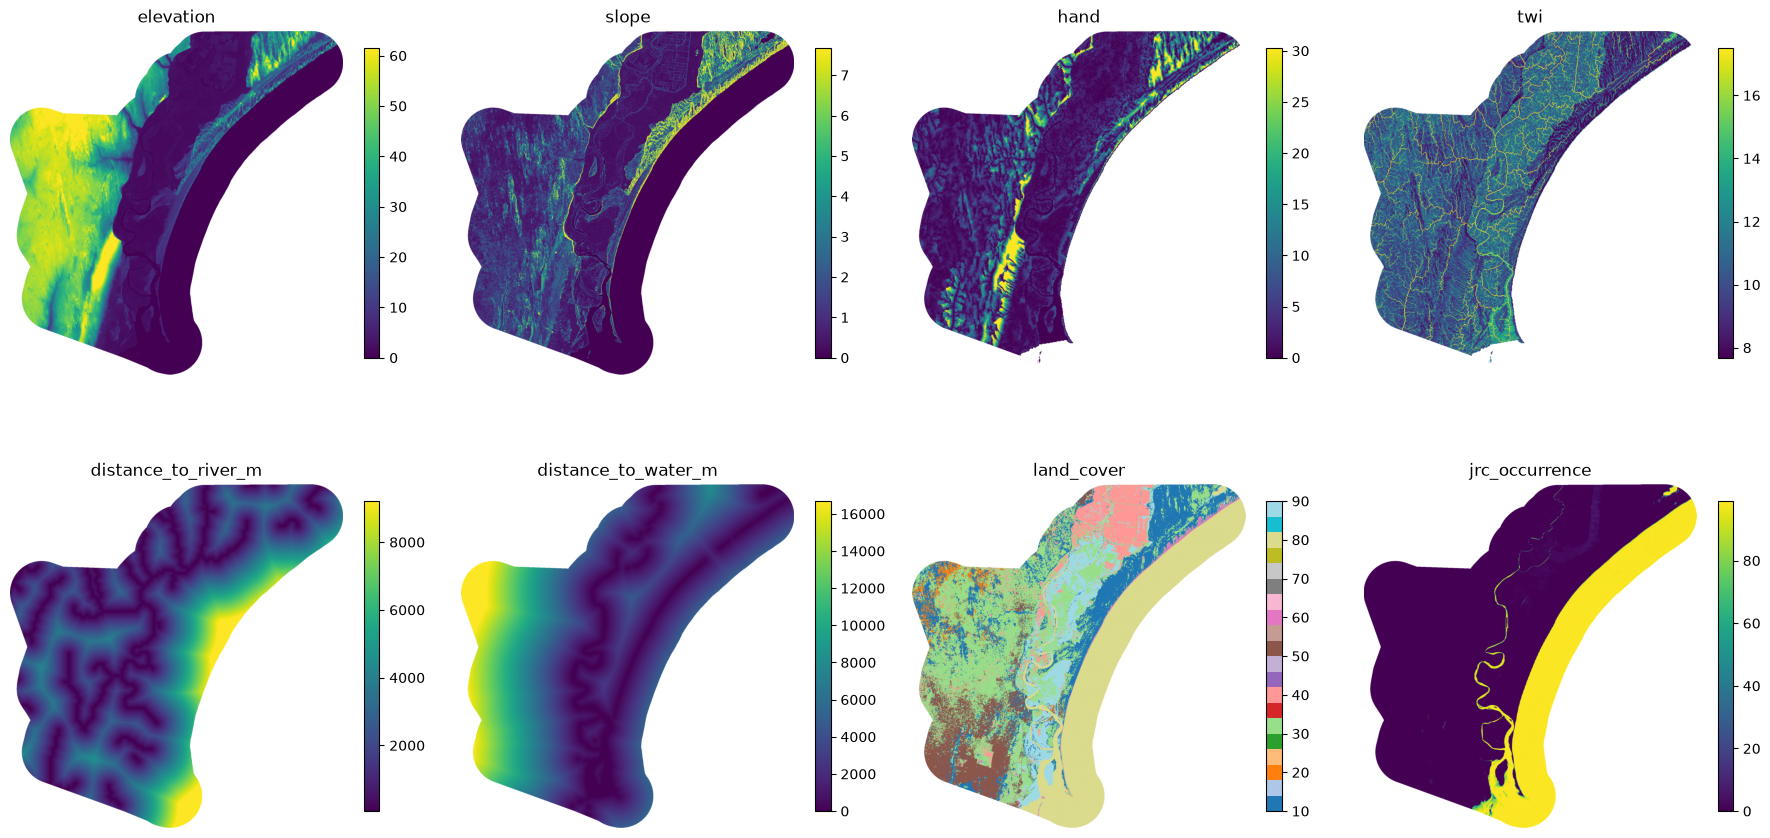

In [3]:
show = ["elevation", "slope", "hand", "twi", "distance_to_river_m", "distance_to_water_m", "land_cover", "jrc_occurrence"]
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, name in zip(axes.flat, show):
    data = np.where(inside, stack[name], np.nan)
    lo, hi = np.nanpercentile(data, [2, 98])
    im = ax.imshow(data, cmap="tab20" if name == "land_cover" else "viridis", vmin=lo, vmax=hi)
    ax.set_title(name); ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout(); plt.savefig(REPORTS / "21_stack_estatico.png", dpi=110)

## 2. Confirmar o alinhamento de todos os rasters

Todos os GeoTIFF do projeto em UTM têm de ter a mesma extensão e um píxel de 10
ou 30 m. A tabela final deve estar vazia.

In [4]:
import rasterio

grid30 = G.load_grid(cfg)
problems, checked = [], 0
for f in (ROOT / "data").rglob("*.tif"):
    if ".part" in f.name:
        continue
    with rasterio.open(f) as src:
        if src.crs is None or src.crs.to_epsg() != 32736:
            continue
        checked += 1
        if not (np.allclose(tuple(src.bounds), grid30.bounds) and src.res[0] in (10, 30)):
            problems.append({"ficheiro": str(f.relative_to(ROOT)), "pixel": src.res[0]})
print(f"{checked} rasters verificados, {len(problems)} fora da grelha")
pd.DataFrame(problems)

829 rasters verificados, 0 fora da grelha


""


## 3. Domínio de modelação e blocos espaciais

retângulo descarregado : 2,838 km²
zona de estudo         : 1,534 km² (distrito + 5 km)
domínio de modelação   : 1,213 km² (zona de estudo com dados de terreno)
  dentro do distrito   : 705 km²
  água permanente      : 35 km² (ocorrência JRC >= 75 %)
  terreno baixo        : 869 km² (HAND <= 5 m)
blocos de 3 km           : 168, repartidos por 5 grupos


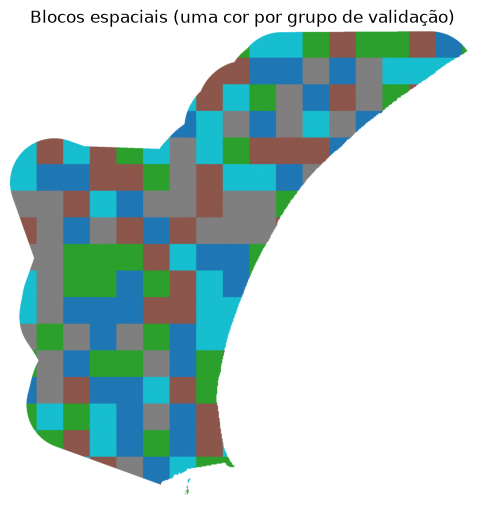

In [5]:
frame = training.sampling_frame(cfg)
km2 = lambda mask: mask.sum() * 900 / 1e6
print(f"retângulo descarregado : {grid30.width * grid30.height * 900 / 1e6:,.0f} km²")
print(f"zona de estudo         : {km2(masks['study']):,.0f} km² (distrito + {cfg['aoi']['imagery_buffer_km']} km)")
print(f"domínio de modelação   : {km2(frame['domain']):,.0f} km² (zona de estudo com dados de terreno)")
print(f"  dentro do distrito   : {km2(frame['domain'] & frame['district']):,.0f} km²")
print(f"  água permanente      : {km2(frame['domain'] & frame['permanent']):,.0f} km² (ocorrência JRC >= {P['permanent_water_occurrence']} %)")
print(f"  terreno baixo        : {km2(frame['domain'] & frame['low']):,.0f} km² (HAND <= {P['low_hand_m']} m)")
print(f"blocos de {P['block_size_m'] / 1000:.0f} km           : {len(frame['fold_of'])}, repartidos por {P['n_folds']} grupos")

folds = np.full(frame["block"].shape, np.nan)
for block, fold in frame["fold_of"].items():
    folds[(frame["block"] == block) & frame["domain"]] = fold
plt.figure(figsize=(6, 7)); plt.imshow(folds, cmap="tab10"); plt.axis("off")
plt.title("Blocos espaciais (uma cor por grupo de validação)")
plt.savefig(REPORTS / "21_blocos_espaciais.png", dpi=110)

Os blocos servem para a validação da Semana 3: píxeis vizinhos são quase iguais,
por isso treino e teste nunca devem ter píxeis do mesmo bloco.